# SaTML paper figures and tables

Notebook version of `make_figures.py`. Reads the CSV result files in this folder (`summary.csv`: one row per architecture x seed x forgotten_domain x method) and writes:

- `figures/fig1_tradeoff`, `fig2_fidelity`, `fig3_domains`, `fig4_ssd_alpha`, `fig5_fisher_geometry`, `fig6_mia` (PDF + PNG)
- `table_main.tex`, `table_mia.tex`, `table_efficiency.tex`, `table_fidelity.tex`
- `stats.json`

Run from the `4methods-fix2` folder (`DATA_DIR` is relative).

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = '.'
FIGDIR = os.path.join(DATA_DIR, 'figures')
os.makedirs(FIGDIR, exist_ok=True)

df = pd.read_csv(os.path.join(DATA_DIR, 'summary.csv'))
df.shape

(288, 40)

## Style, labels, and helpers

In [2]:
plt.rcParams.update({
    "font.size": 7.5,
    "axes.titlesize": 8,
    "axes.labelsize": 7.5,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.5,
    "axes.axisbelow": True,
    "figure.dpi": 200,
    "pdf.fonttype": 42,
})

TEXT = "#0b0b0b"
MUTED = "#52514e"

# validated categorical palette (light mode), color follows the method
COLORS = {
    "scrub_r": "#2a78d6",              # blue
    "ssd_canonical": "#eb6834",        # orange
    "dc_ssd": "#1baf7a",               # aqua
    "rollback_repair": "#eda100",      # yellow
    "dc_ssd_no_contrast": "#4a3aa7",   # violet
    "dc_ssd_no_class_balance": "#e87ba4",  # magenta
}
LABELS = {
    "scrub_r": "SCRUB-R",
    "ssd_canonical": "SSD",
    "dc_ssd": "DC-SSD",
    "rollback_repair": "Rollback+Repair",
    "dc_ssd_no_contrast": "DC-SSD w/o contrast",
    "dc_ssd_no_class_balance": "DC-SSD w/o class bal.",
}
BASE_METHODS = ["scrub_r", "ssd_canonical", "dc_ssd",
                "dc_ssd_no_contrast", "dc_ssd_no_class_balance", "rollback_repair"]
ARCHS = ["mlp", "numerical_feature_transformer"]
ARCH_LABEL = {"mlp": "MLP", "numerical_feature_transformer": "NFT"}
ARCH_MARKER = {"mlp": "o", "numerical_feature_transformer": "^"}
DOMAINS = ["NF-UNSW-NB15", "NF-ToN-IoT", "NF-BoT-IoT", "NF-CSE-CIC-IDS2018"]
DOM_SHORT = {"NF-UNSW-NB15": "UNSW-NB15", "NF-ToN-IoT": "ToN-IoT",
             "NF-BoT-IoT": "BoT-IoT", "NF-CSE-CIC-IDS2018": "CIC-IDS2018"}

base = df[df["method"].isin(BASE_METHODS)].copy()
base["retained_f1_gap"] = base["retrained_retained_macro_f1"] - base["method_retained_macro_f1"]


def mean_ci(x):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)
    m = x.mean()
    if n < 2:
        return m, 0.0
    # t multiplier for 95% CI, small-n table
    tval = {2: 12.71, 3: 4.303, 6: 2.571, 12: 2.201, 24: 2.069}.get(n, 1.96)
    return m, tval * x.std(ddof=1) / np.sqrt(n)

## Fig 1: efficiency vs fidelity trade-off

The "no method in the good corner" figure. Left: retained-utility gap vs retrained (macro-F1). Right: forgotten-domain F1 gap vs retrained. x = mean speed-up, y = mean ± 95% CI per (method, architecture).

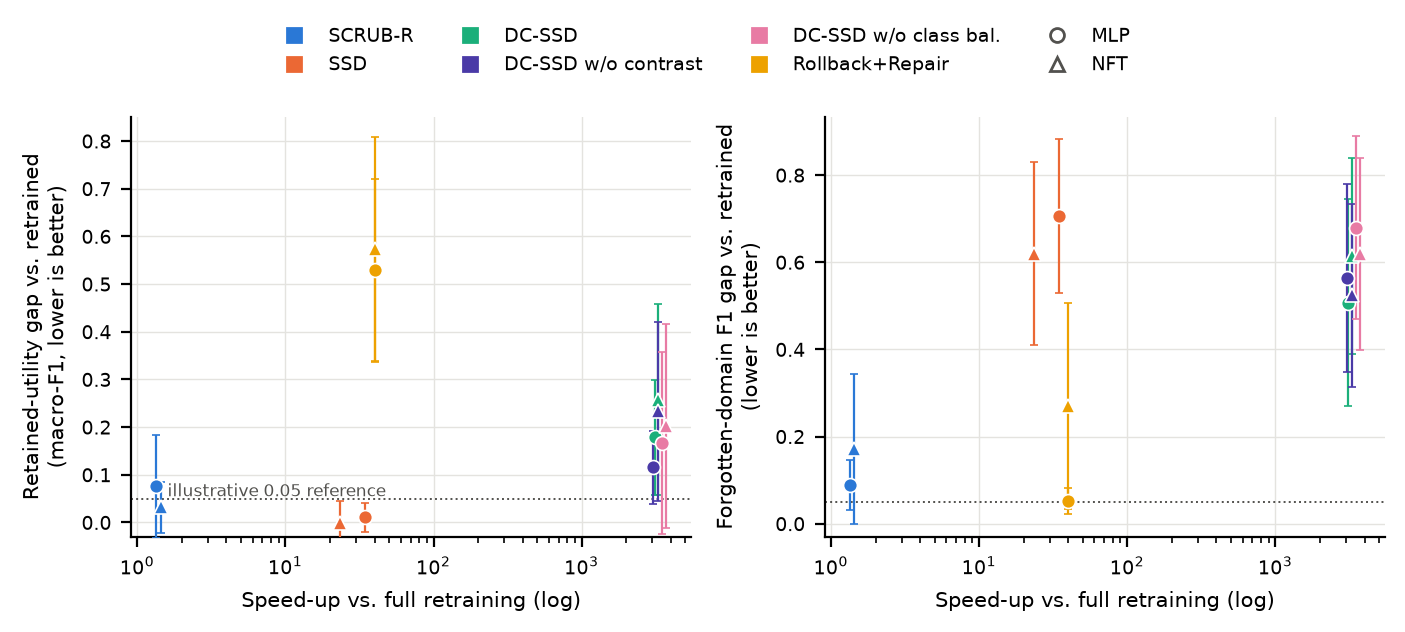

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.05, 3.0))
panels = [
    ("retained_f1_gap", "Retained-utility gap vs. retrained\n(macro-F1, lower is better)"),
    ("method_forgotten_abs_f1_gap_from_retrained",
     "Forgotten-domain F1 gap vs. retrained\n(lower is better)"),
]
for ax, (col, ylab) in zip(axes, panels):
    for meth in BASE_METHODS:
        for arch in ARCHS:
            sub = base[(base["method"] == meth) & (base["architecture"] == arch)]
            x = sub["online_speedup_vs_retraining_optimization"].mean()
            y, err = mean_ci(sub[col])
            ax.errorbar(x, y, yerr=err, fmt=ARCH_MARKER[arch], ms=5,
                        color=COLORS[meth], mec="white", mew=0.6,
                        elinewidth=0.8, capsize=1.5, zorder=3)
    ax.set_xscale("log")
    ax.set_xlabel("Speed-up vs. full retraining (log)")
    ax.set_ylabel(ylab)
    ax.axhline(0.05, color=MUTED, lw=0.7, ls=":")
    ax.set_ylim(bottom=-0.03)
axes[0].annotate("illustrative 0.05 reference", xy=(1.6, 0.055), fontsize=6.2, color=MUTED)
handles = [plt.Line2D([], [], color=COLORS[m], marker="s", ls="", ms=5,
                      label=LABELS[m]) for m in BASE_METHODS]
handles += [plt.Line2D([], [], color=MUTED, marker=ARCH_MARKER[a], ls="", ms=5,
                       mfc="none", label=ARCH_LABEL[a]) for a in ARCHS]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, 1.04))
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(os.path.join(FIGDIR, "fig1_tradeoff.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(FIGDIR, "fig1_tradeoff.png"), bbox_inches="tight")
plt.show()

## Fig 2: fidelity to the retrained gold standard

Forest/dot plot, mean ± 95% CI for retained macro-F1 gap, forgotten F1 gap, and MIA AUC gap.

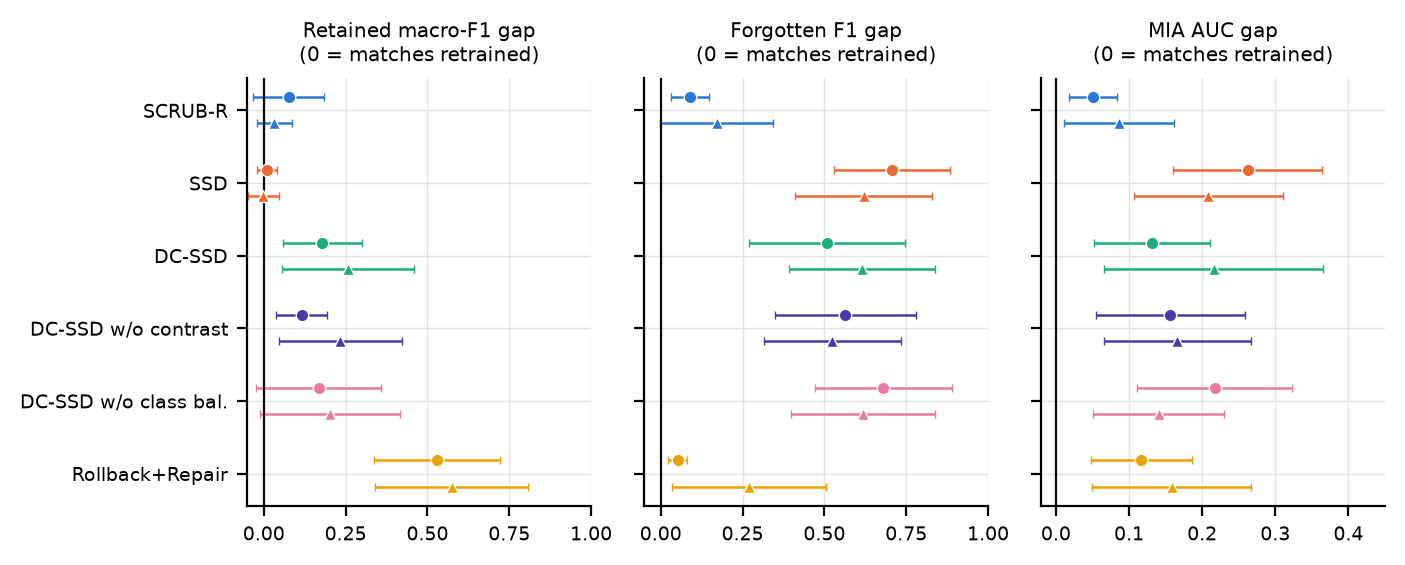

In [4]:
metrics = [
    ("retained_f1_gap", "Retained macro-F1 gap", (-0.05, 1.0)),
    ("method_forgotten_abs_f1_gap_from_retrained", "Forgotten F1 gap", (-0.05, 1.0)),
    ("method_abs_mia_auc_gap_from_retrained", "MIA AUC gap", (-0.02, 0.45)),
]
fig, axes = plt.subplots(1, 3, figsize=(7.05, 2.85), sharey=True)
ypos = np.arange(len(BASE_METHODS))[::-1]
for ax, (col, title, xlim) in zip(axes, metrics):
    for i, meth in enumerate(BASE_METHODS):
        for k, arch in enumerate(ARCHS):
            sub = base[(base["method"] == meth) & (base["architecture"] == arch)]
            m, err = mean_ci(sub[col])
            ax.errorbar(m, ypos[i] + (0.18 if arch == "mlp" else -0.18),
                        xerr=err, fmt=ARCH_MARKER[arch], ms=4.5,
                        color=COLORS[meth], mec="white", mew=0.5,
                        elinewidth=0.9, capsize=1.5)
    ax.axvline(0, color=TEXT, lw=0.8)
    ax.set_title(title + "\n(0 = matches retrained)", fontsize=7.2)
    ax.set_xlim(xlim)
axes[0].set_yticks(ypos)
axes[0].set_yticklabels([LABELS[m] for m in BASE_METHODS])
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "fig2_fidelity.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(FIGDIR, "fig2_fidelity.png"), bbox_inches="tight")
plt.show()

## Fig 3: per-domain heterogeneity

Heatmap of retained macro-F1 by method x forgotten domain, one panel per architecture.

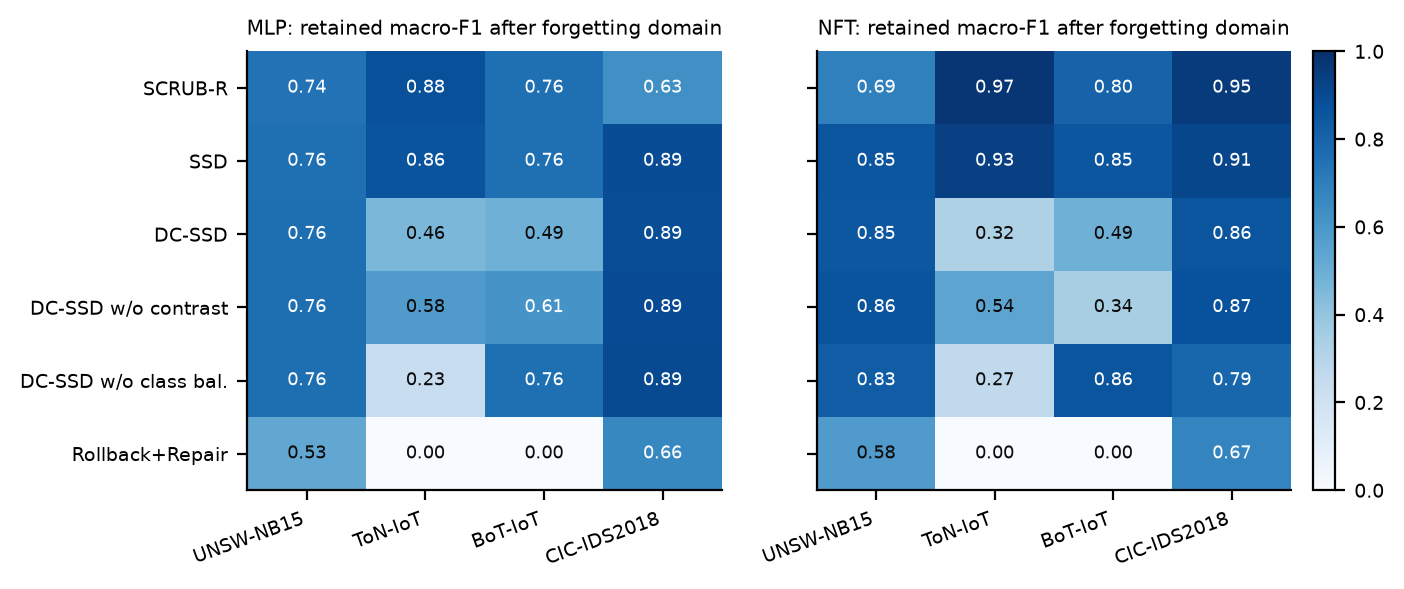

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.05, 2.85))
for ax, arch in zip(axes, ARCHS):
    grid = np.zeros((len(BASE_METHODS), len(DOMAINS)))
    for i, meth in enumerate(BASE_METHODS):
        for j, dom in enumerate(DOMAINS):
            sub = base[(base["method"] == meth) & (base["architecture"] == arch)
                       & (base["forgotten_domain"] == dom)]
            grid[i, j] = sub["method_retained_macro_f1"].mean()
    im = ax.imshow(grid, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid[i, j]
            ax.text(j, i, "%.2f" % v, ha="center", va="center", fontsize=6.5,
                    color="white" if v > 0.6 else TEXT)
    ax.set_xticks(range(len(DOMAINS)))
    ax.set_xticklabels([DOM_SHORT[d] for d in DOMAINS], rotation=20, ha="right")
    ax.set_yticks(range(len(BASE_METHODS)))
    ax.set_yticklabels([LABELS[m] for m in BASE_METHODS] if arch == "mlp" else [])
    ax.set_title("%s: retained macro-F1 after forgetting domain" % ARCH_LABEL[arch],
                 fontsize=7.2)
    ax.grid(False)
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02)
fig.savefig(os.path.join(FIGDIR, "fig3_domains.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(FIGDIR, "fig3_domains.png"), bbox_inches="tight")
plt.show()

## Fig 4: SSD alpha analysis

Structural no-ops (identity outcomes) and F1 outcomes across the alpha sweep. `ssd_canonical` is the default alpha = 10 (`resolved_config.json`).

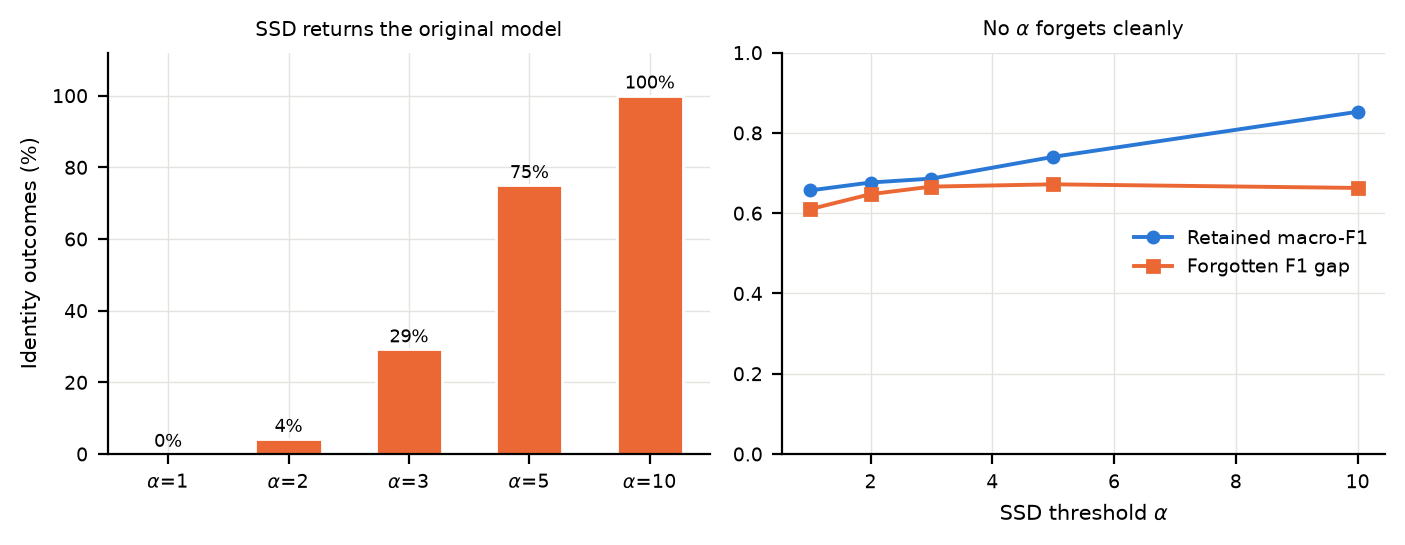

In [6]:
ssd_variants = ["ssd_canonical@alpha=1", "ssd_canonical@alpha=2",
                "ssd_canonical@alpha=3", "ssd_canonical@alpha=5", "ssd_canonical"]
alphas = [1, 2, 3, 5, 10]
noop_frac, ret_f1, fgt_gap = [], [], []
for v in ssd_variants:
    sub = df[df["method"] == v]
    noop_frac.append((sub["is_identity_map"].astype(str) == "True").mean())
    ret_f1.append(sub["method_retained_macro_f1"].mean())
    fgt_gap.append(sub["method_forgotten_abs_f1_gap_from_retrained"].mean())

fig, axes = plt.subplots(1, 2, figsize=(7.05, 2.75))
ax = axes[0]
ax.bar(range(len(alphas)), [f * 100 for f in noop_frac], color="#eb6834",
       width=0.55, edgecolor="white")
ax.set_xticks(range(len(alphas)))
ax.set_xticklabels([r"$\alpha$=%d" % a for a in alphas])
ax.set_ylabel("Identity outcomes (%)")
ax.set_title("SSD returns the original model", fontsize=7.2)
for i, f in enumerate(noop_frac):
    ax.text(i, f * 100 + 2, "%d%%" % round(f * 100), ha="center", fontsize=6.5)
ax.set_ylim(0, 112)

ax = axes[1]
ax.plot(alphas, ret_f1, "-o", color="#2a78d6", ms=4, lw=1.4, label="Retained macro-F1")
ax.plot(alphas, fgt_gap, "-s", color="#eb6834", ms=4, lw=1.4,
        label="Forgotten F1 gap")
ax.set_xlabel(r"SSD threshold $\alpha$")
ax.set_ylim(0, 1)
ax.set_title("No $\\alpha$ forgets cleanly", fontsize=7.2)
ax.legend(frameon=False, loc="center right")
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "fig4_ssd_alpha.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(FIGDIR, "fig4_ssd_alpha.png"), bbox_inches="tight")
plt.show()

## Table 1: main results (`table_main.tex`)

In [7]:
rows_tex = []
for arch in ARCHS:
    for meth in BASE_METHODS:
        sub = base[(base["method"] == meth) & (base["architecture"] == arch)]
        cells = []
        for col in ["method_retained_macro_f1",
                    "method_forgotten_abs_f1_gap_from_retrained",
                    "method_abs_mia_auc_gap_from_retrained",
                    "method_forgotten_prediction_agreement_with_retrained"]:
            m, err = mean_ci(sub[col])
            cells.append("%.3f {\\scriptsize$\\pm$%.3f}" % (m, err))
        speed = sub["online_speedup_vs_retraining_optimization"].mean()
        speed_s = ("%.0f$\\times$" % speed) if speed >= 10 else ("%.1f$\\times$" % speed)
        rows_tex.append("%s & %s & %s & %s \\\\" % (
            ARCH_LABEL[arch], LABELS[meth].replace("w/o ", "w/o~"),
            " & ".join(cells), speed_s))
header = r"""\begin{tabular}{llccccc}
\toprule
Arch. & Method & Retained macro-F1 $\uparrow$ & Forgotten F1 gap $\downarrow$ &
MIA AUC gap $\downarrow$ & Agreement $\uparrow$ & Speed-up \\
\midrule
"""
footer = r"""\bottomrule
\end{tabular}
"""
table_main = header + "\n".join(rows_tex) + "\n" + footer
with open(os.path.join(DATA_DIR, "table_main.tex"), "w") as f:
    f.write(table_main)
print(table_main)

\begin{tabular}{llccccc}
\toprule
Arch. & Method & Retained macro-F1 $\uparrow$ & Forgotten F1 gap $\downarrow$ &
MIA AUC gap $\downarrow$ & Agreement $\uparrow$ & Speed-up \\
\midrule
MLP & SCRUB-R & 0.751 {\scriptsize$\pm$0.070} & 0.089 {\scriptsize$\pm$0.057} & 0.051 {\scriptsize$\pm$0.033} & 0.726 {\scriptsize$\pm$0.138} & 1.3$\times$ \\
MLP & SSD & 0.817 {\scriptsize$\pm$0.040} & 0.706 {\scriptsize$\pm$0.177} & 0.262 {\scriptsize$\pm$0.102} & 0.364 {\scriptsize$\pm$0.145} & 34$\times$ \\
MLP & DC-SSD & 0.649 {\scriptsize$\pm$0.134} & 0.508 {\scriptsize$\pm$0.237} & 0.132 {\scriptsize$\pm$0.080} & 0.536 {\scriptsize$\pm$0.185} & 3115$\times$ \\
MLP & DC-SSD w/o~contrast & 0.712 {\scriptsize$\pm$0.088} & 0.563 {\scriptsize$\pm$0.215} & 0.156 {\scriptsize$\pm$0.101} & 0.506 {\scriptsize$\pm$0.151} & 3039$\times$ \\
MLP & DC-SSD w/o~class bal. & 0.660 {\scriptsize$\pm$0.175} & 0.680 {\scriptsize$\pm$0.209} & 0.217 {\scriptsize$\pm$0.106} & 0.349 {\scriptsize$\pm$0.177} & 3495$\times$ 

## `stats.json`: headline numbers per architecture/method

In [8]:
stats = {}
for arch in ARCHS:
    for meth in BASE_METHODS + ["ssd_canonical@alpha=1", "scrub_r@lr=0.0001",
                                "scrub_r@lr=0.001"]:
        sub = df[(df["method"] == meth) & (df["architecture"] == arch)]
        if not len(sub):
            continue
        stats["%s/%s" % (arch, meth)] = {
            "retained_f1": round(sub["method_retained_macro_f1"].mean(), 4),
            "retrained_retained_f1": round(sub["retrained_retained_macro_f1"].mean(), 4),
            "forgotten_f1_gap": round(sub["method_forgotten_abs_f1_gap_from_retrained"].mean(), 4),
            "mia_gap": round(sub["method_abs_mia_auc_gap_from_retrained"].mean(), 4),
            "agreement": round(sub["method_forgotten_prediction_agreement_with_retrained"].mean(), 4),
            "speedup": round(sub["online_speedup_vs_retraining_optimization"].mean(), 2),
            "identity_frac": round((sub["is_identity_map"].astype(str) == "True").mean(), 3),
        }
stats["retrain_seconds_mean"] = round(
    df["full_retraining_optimization_seconds"].mean(), 1)
with open(os.path.join(DATA_DIR, "stats.json"), "w") as f:
    json.dump(stats, f, indent=2, sort_keys=True)
pd.DataFrame({k: v for k, v in stats.items() if isinstance(v, dict)}).T

,retained_f1,retrained_retained_f1,forgotten_f1_gap,mia_gap,agreement,speedup,identity_frac
mlp/scrub_r,0.7512,0.8275,0.0893,0.0508,0.7262,1.35,0.0
mlp/ssd_canonical,0.8166,0.8275,0.7063,0.2623,0.3638,34.42,1.0
mlp/dc_ssd,0.6485,0.8275,0.5076,0.1316,0.5361,3114.89,0.0
mlp/dc_ssd_no_contrast,0.7120,0.8275,0.5635,0.1564,0.5062,3039.34,0.0
mlp/dc_ssd_no_class_balance,0.6603,0.8275,0.6796,0.2171,0.3492,3495.36,0.0
mlp/rollback_repair,0.2988,0.8275,0.0522,0.1168,0.7561,40.03,0.0
mlp/ssd_canonical@alpha=1,0.6886,0.8275,0.5912,0.1786,0.4376,33.76,0.0
mlp/scrub_r@lr=0.0001,0.8276,0.8275,0.1176,0.1118,0.7758,1.34,0.0
mlp/scrub_r@lr=0.001,0.7736,0.8275,0.2169,0.0662,0.6497,1.34,0.0
numerical_feature_transformer/scrub_r,0.8554,0.8874,0.1713,0.0866,0.6251,1.44,0.0


## Fig 5: Fisher geometry

Why ratio thresholding fails: strip plot of the cosine similarity between forget and reference Fisher per method (only SSD-family methods have this diagnostic).

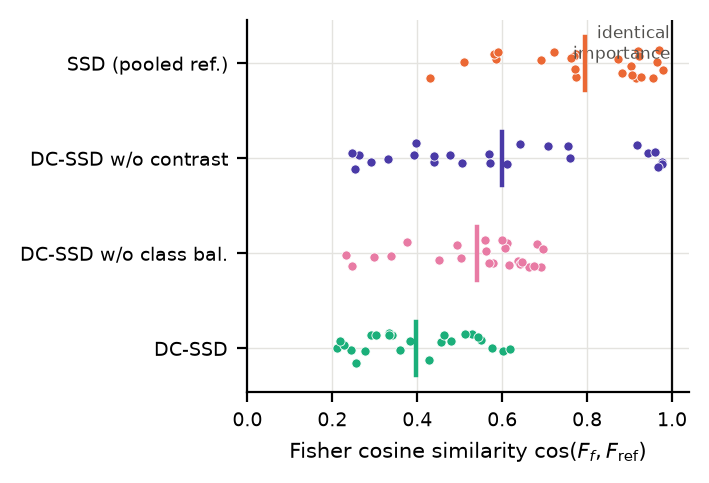

In [9]:
diag = pd.read_csv(os.path.join(DATA_DIR, "all_method_diagnostics.csv"))
strip_order = ["ssd_canonical", "dc_ssd_no_contrast",
               "dc_ssd_no_class_balance", "dc_ssd"]
STRIP_LABELS = dict(LABELS)
STRIP_LABELS["ssd_canonical"] = "SSD (pooled ref.)"
fig, ax = plt.subplots(figsize=(3.45, 2.55))
rng = np.random.default_rng(0)
for i, meth in enumerate(strip_order):
    sub = diag[diag["method"] == meth][
        "reference_forget_fisher_cosine_similarity"].dropna()
    y = (np.full(len(sub), len(strip_order) - 1 - i, dtype=float)
         + rng.uniform(-0.16, 0.16, len(sub)))
    ax.scatter(sub, y, s=11, color=COLORS[meth], edgecolors="white",
               linewidths=0.3, zorder=3)
    ax.plot([sub.mean()] * 2,
            [len(strip_order) - 1 - i - 0.28, len(strip_order) - 1 - i + 0.28],
            color=COLORS[meth], lw=1.6, zorder=4)
ax.axvline(1.0, color=TEXT, lw=0.8)
ax.text(0.995, 3.42, "identical\nimportance", ha="right", va="top",
        fontsize=6.2, color=MUTED)
ax.set_yticks(range(len(strip_order))[::-1])
ax.set_yticklabels([STRIP_LABELS[m] for m in strip_order])
ax.set_xlabel(r"Fisher cosine similarity $\cos(F_f,F_{\mathrm{ref}})$")
ax.set_xlim(0, 1.04)
fig.subplots_adjust(left=0.34, right=0.98, bottom=0.24, top=0.97)
fig.savefig(os.path.join(FIGDIR, "fig5_fisher_geometry.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(FIGDIR, "fig5_fisher_geometry.png"), bbox_inches="tight")
plt.show()

## Fig 6: MIA audit

MIA loss AUC and TPR at 1% FPR per model type (`fixed_fpr = 0.01` in `resolved_config.json`); dashed line = retrained reference, dotted = chance.

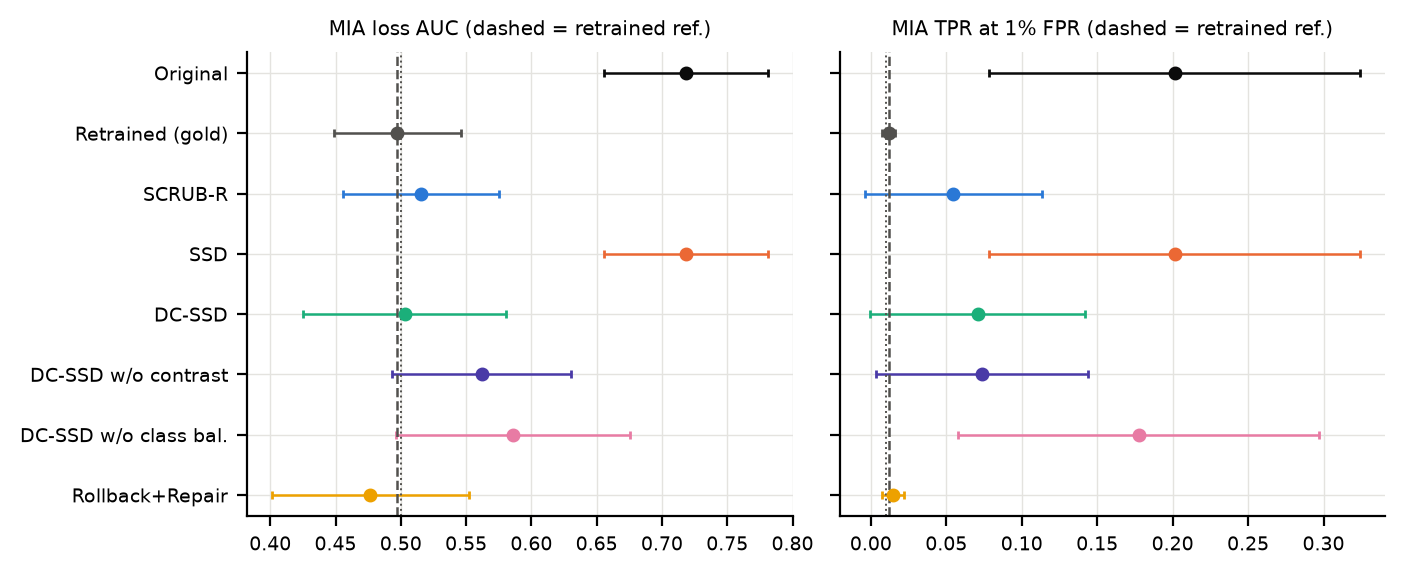

In [10]:
mia = pd.read_csv(os.path.join(DATA_DIR, "all_membership_inference.csv"))
order = ["original", "retrained", "scrub_r", "ssd_canonical", "dc_ssd",
         "dc_ssd_no_contrast", "dc_ssd_no_class_balance", "rollback_repair"]
mlabels = {"original": "Original", "retrained": "Retrained (gold)"}
mlabels.update(LABELS)
fig, axes = plt.subplots(1, 2, figsize=(7.05, 2.9))
for ax, col, title, chance in [
        (axes[0], "mia_loss_auc", "MIA loss AUC", 0.5),
        (axes[1], "mia_tpr_at_fixed_fpr", "MIA TPR at 1% FPR", 0.01)]:
    ypos = np.arange(len(order))[::-1]
    for i, name in enumerate(order):
        sub = mia[mia["model"] == name]
        mval, err = mean_ci(sub[col])
        c = COLORS.get(name, "#52514e" if name == "retrained" else "#0b0b0b")
        ax.errorbar(mval, ypos[i], xerr=err, fmt="o", ms=4, color=c,
                    elinewidth=0.9, capsize=1.5)
    ax.axvline(chance, color=MUTED, lw=0.7, ls=":")
    ret_m, _ = mean_ci(mia[mia["model"] == "retrained"][col])
    ax.axvline(ret_m, color="#52514e", lw=0.9, ls="--")
    ax.set_yticks(ypos)
    ax.set_yticklabels([mlabels[n] for n in order] if col == "mia_loss_auc" else [])
    ax.set_title(title + " (dashed = retrained ref.)", fontsize=7.2)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "fig6_mia.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(FIGDIR, "fig6_mia.png"), bbox_inches="tight")
plt.show()

## Table 2: MIA (`table_mia.tex`)

In [11]:
rows = []
for name in order:
    sub = mia[mia["model"] == name]
    cells = []
    for col in ["mia_loss_auc", "mia_advantage", "mia_tpr_at_fixed_fpr"]:
        mval, err = mean_ci(sub[col])
        cells.append("%.3f {\\scriptsize$\\pm$%.3f}" % (mval, err))
    rows.append("%s & %s \\\\" % (mlabels[name], " & ".join(cells)))
header = r"""\begin{tabular}{lccc}
\toprule
Model & MIA AUC & Advantage & TPR@1\%FPR \\
\midrule
"""
footer = r"""\bottomrule
\end{tabular}
"""
table_mia = header + "\n".join(rows) + "\n" + footer
with open(os.path.join(DATA_DIR, "table_mia.tex"), "w") as f:
    f.write(table_mia)
print(table_mia)

\begin{tabular}{lccc}
\toprule
Model & MIA AUC & Advantage & TPR@1\%FPR \\
\midrule
Original & 0.718 {\scriptsize$\pm$0.063} & 0.402 {\scriptsize$\pm$0.112} & 0.201 {\scriptsize$\pm$0.123} \\
Retrained (gold) & 0.497 {\scriptsize$\pm$0.049} & 0.149 {\scriptsize$\pm$0.071} & 0.012 {\scriptsize$\pm$0.004} \\
SCRUB-R & 0.516 {\scriptsize$\pm$0.060} & 0.148 {\scriptsize$\pm$0.082} & 0.054 {\scriptsize$\pm$0.059} \\
SSD & 0.718 {\scriptsize$\pm$0.063} & 0.402 {\scriptsize$\pm$0.112} & 0.201 {\scriptsize$\pm$0.123} \\
DC-SSD & 0.503 {\scriptsize$\pm$0.078} & 0.164 {\scriptsize$\pm$0.086} & 0.071 {\scriptsize$\pm$0.071} \\
DC-SSD w/o contrast & 0.562 {\scriptsize$\pm$0.069} & 0.229 {\scriptsize$\pm$0.091} & 0.073 {\scriptsize$\pm$0.070} \\
DC-SSD w/o class bal. & 0.586 {\scriptsize$\pm$0.089} & 0.266 {\scriptsize$\pm$0.123} & 0.177 {\scriptsize$\pm$0.120} \\
Rollback+Repair & 0.477 {\scriptsize$\pm$0.075} & 0.167 {\scriptsize$\pm$0.086} & 0.014 {\scriptsize$\pm$0.007} \\
\bottomrule
\end{tabu

## Table 3: efficiency (`table_efficiency.tex`)

In [12]:
eff = pd.read_csv(os.path.join(DATA_DIR, "all_efficiency.csv"))
eff = eff[eff["method"].isin(BASE_METHODS)]
rows = []
for meth in BASE_METHODS:
    sub = eff[eff["method"] == meth]
    online = sub["online_seconds"].mean()
    prep = sub["offline_preparation_seconds"].fillna(0).mean()
    storage = sub["online_temporary_storage_bytes"].mean() / 1e6
    steps = sub["online_optimizer_steps"].mean()
    retrain = sub["full_retraining_optimization_seconds"].mean()
    speed = retrain / max(online, 1e-9)
    speed_s = ("%.0f$\\times$" % speed) if speed >= 10 else ("%.1f$\\times$" % speed)
    rows.append("%s & %.2f & %.1f & %.1f & %.0f & %.0f & %s \\\\" % (
        LABELS[meth].replace("w/o ", "w/o~"), online, prep, storage, steps,
        retrain, speed_s))
header = r"""\begin{tabular}{lcccccc}
\toprule
Method & Online (s) & Offline (s) & Store (MB) & Steps & Retrain (s) & Speed-up \\
\midrule
"""
footer = r"""\bottomrule
\end{tabular}
"""
table_efficiency = header + "\n".join(rows) + "\n" + footer
with open(os.path.join(DATA_DIR, "table_efficiency.tex"), "w") as f:
    f.write(table_efficiency)
print(table_efficiency)

\begin{tabular}{lcccccc}
\toprule
Method & Online (s) & Offline (s) & Store (MB) & Steps & Retrain (s) & Speed-up \\
\midrule
SCRUB-R & 86.26 & 0.0 & 0.2 & 11282 & 119 & 1.4$\times$ \\
SSD & 5.85 & 23.3 & 0.1 & 0 & 119 & 20$\times$ \\
DC-SSD & 0.04 & 23.4 & 0.2 & 0 & 119 & 3178$\times$ \\
DC-SSD w/o~contrast & 0.04 & 23.4 & 0.2 & 0 & 119 & 3139$\times$ \\
DC-SSD w/o~class bal. & 0.03 & 23.4 & 0.2 & 0 & 119 & 3552$\times$ \\
Rollback+Repair & 2.97 & 0.0 & 0.2 & 500 & 119 & 40$\times$ \\
\bottomrule
\end{tabular}



## Table 4: counterfactual fidelity detail (`table_fidelity.tex`)

In [13]:
rows = []
for meth in BASE_METHODS:
    sub = base[base["method"] == meth]
    cells = []
    for col in ["method_forgotten_prediction_agreement_with_retrained",
                "method_forgotten_js_divergence_from_retrained",
                "method_forgotten_linear_cka_to_retrained",
                "method_retained_macro_linear_cka_to_retrained"]:
        mval, err = mean_ci(sub[col])
        cells.append("%.3f {\\scriptsize$\\pm$%.3f}" % (mval, err))
    rows.append("%s & %s \\\\" % (LABELS[meth].replace("w/o ", "w/o~"),
                                  " & ".join(cells)))
header = r"""\begin{tabular}{lcccc}
\toprule
Method & Agreement $\uparrow$ & JS div. $\downarrow$ & CKA (forgot) $\uparrow$ & CKA (ret.) $\uparrow$ \\
\midrule
"""
footer = r"""\bottomrule
\end{tabular}
"""
table_fidelity = header + "\n".join(rows) + "\n" + footer
with open(os.path.join(DATA_DIR, "table_fidelity.tex"), "w") as f:
    f.write(table_fidelity)
print(table_fidelity)

\begin{tabular}{lcccc}
\toprule
Method & Agreement $\uparrow$ & JS div. $\downarrow$ & CKA (forgot) $\uparrow$ & CKA (ret.) $\uparrow$ \\
\midrule
SCRUB-R & 0.676 {\scriptsize$\pm$0.115} & 0.150 {\scriptsize$\pm$0.058} & 0.522 {\scriptsize$\pm$0.086} & 0.664 {\scriptsize$\pm$0.056} \\
SSD & 0.414 {\scriptsize$\pm$0.110} & 0.277 {\scriptsize$\pm$0.076} & 0.543 {\scriptsize$\pm$0.104} & 0.793 {\scriptsize$\pm$0.042} \\
DC-SSD & 0.485 {\scriptsize$\pm$0.126} & 0.210 {\scriptsize$\pm$0.064} & 0.532 {\scriptsize$\pm$0.115} & 0.603 {\scriptsize$\pm$0.089} \\
DC-SSD w/o~contrast & 0.522 {\scriptsize$\pm$0.114} & 0.207 {\scriptsize$\pm$0.061} & 0.544 {\scriptsize$\pm$0.114} & 0.650 {\scriptsize$\pm$0.073} \\
DC-SSD w/o~class bal. & 0.401 {\scriptsize$\pm$0.124} & 0.272 {\scriptsize$\pm$0.075} & 0.441 {\scriptsize$\pm$0.107} & 0.658 {\scriptsize$\pm$0.099} \\
Rollback+Repair & 0.628 {\scriptsize$\pm$0.125} & 0.126 {\scriptsize$\pm$0.041} & 0.389 {\scriptsize$\pm$0.096} & 0.344 {\scriptsize$\pm$